# 02 — Exploratory Data Analysis
**Goal:** understand class balance, the `stab`/`stabf` relationship, feature correlations and how
feature distributions differ between stable and unstable grids.

In [1]:
import sys
from pathlib import Path

# Make the project's src/ package importable when running from notebooks/
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT))
DATA_PATH = PROJECT_ROOT / "data" / "raw" / "electrical_grid_stability.csv"

import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.width", 140)
%matplotlib inline

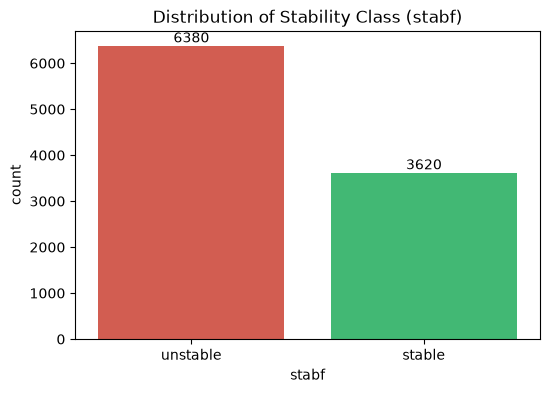

In [2]:
df = pd.read_csv(DATA_PATH)
FEATURES = [c for c in df.columns if c not in ("stab", "stabf")]
PALETTE = {"unstable": "#e74c3c", "stable": "#2ecc71"}

fig, ax = plt.subplots(figsize=(6, 4))
sns.countplot(data=df, x="stabf", hue="stabf", order=["unstable", "stable"], palette=PALETTE, legend=False, ax=ax)
for c in ax.containers:
    ax.bar_label(c, fmt="%d")
ax.set_title("Distribution of Stability Class (stabf)")
plt.show()

**Interpretation:** 6,380 unstable vs 3,620 stable records. Stratified splitting is needed so both train and test sets keep this ratio.

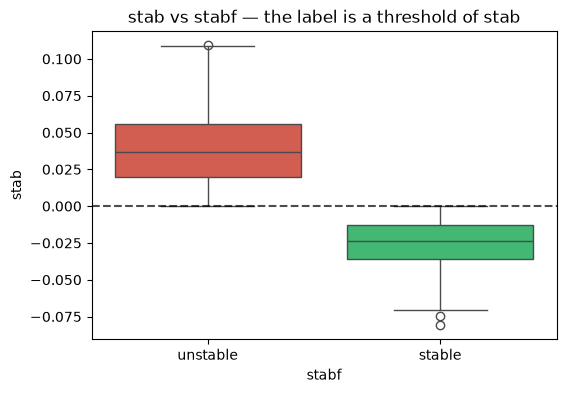

,min,max,mean
stabf,,,
stable,-8.075989e-02,-0.000002,-0.024798
unstable,2.574273e-07,0.109403,0.038727


In [3]:
fig, ax = plt.subplots(figsize=(6, 4))
sns.boxplot(data=df, x="stabf", y="stab", hue="stabf", order=["unstable", "stable"], palette=PALETTE, legend=False, ax=ax)
ax.axhline(0, color="black", ls="--", alpha=0.7)
ax.set_title("stab vs stabf — the label is a threshold of stab")
plt.show()
df.groupby("stabf")["stab"].agg(["min", "max", "mean"])

**Interpretation:** the two boxes do not overlap at all: every stable record has `stab ≤ 0` and every
unstable record has `stab > 0`. Including `stab` would let a model reach ~100% accuracy by learning
one threshold, which says nothing about whether the *operating parameters* predict stability. `stab`
is therefore **excluded** from the feature set for all experiments.

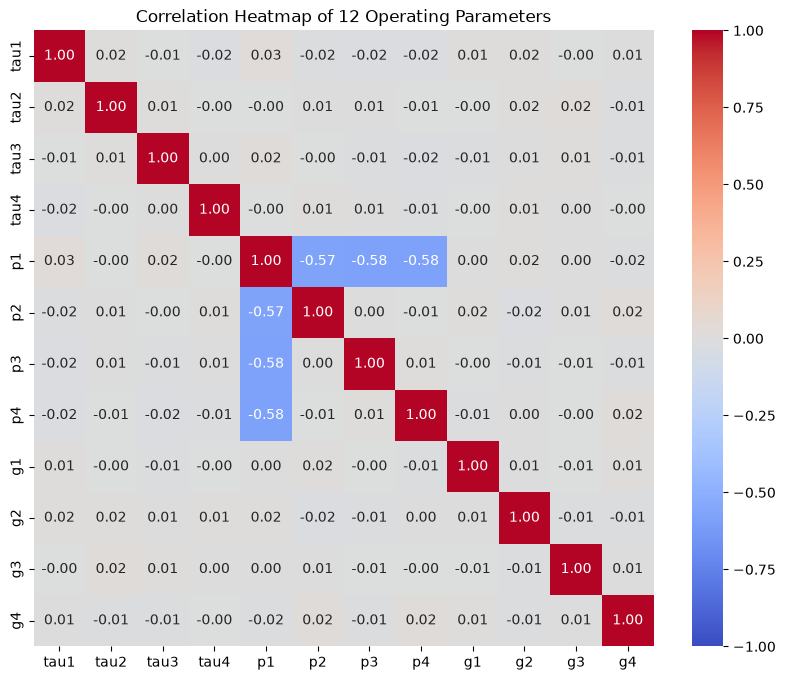

In [4]:
fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(df[FEATURES].corr(), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, ax=ax)
ax.set_title("Correlation Heatmap of 12 Operating Parameters")
plt.show()

**Interpretation:** almost all pairwise correlations are ≈ 0, as expected from independently sampled
simulation inputs. The only notable correlations are between `p1` and each consumer power
(≈ −0.58), which arise from the power-balance constraint `p1 = −(p2 + p3 + p4)`. Pairwise
correlation understates this: `p1` is *perfectly* explained by the other three together.

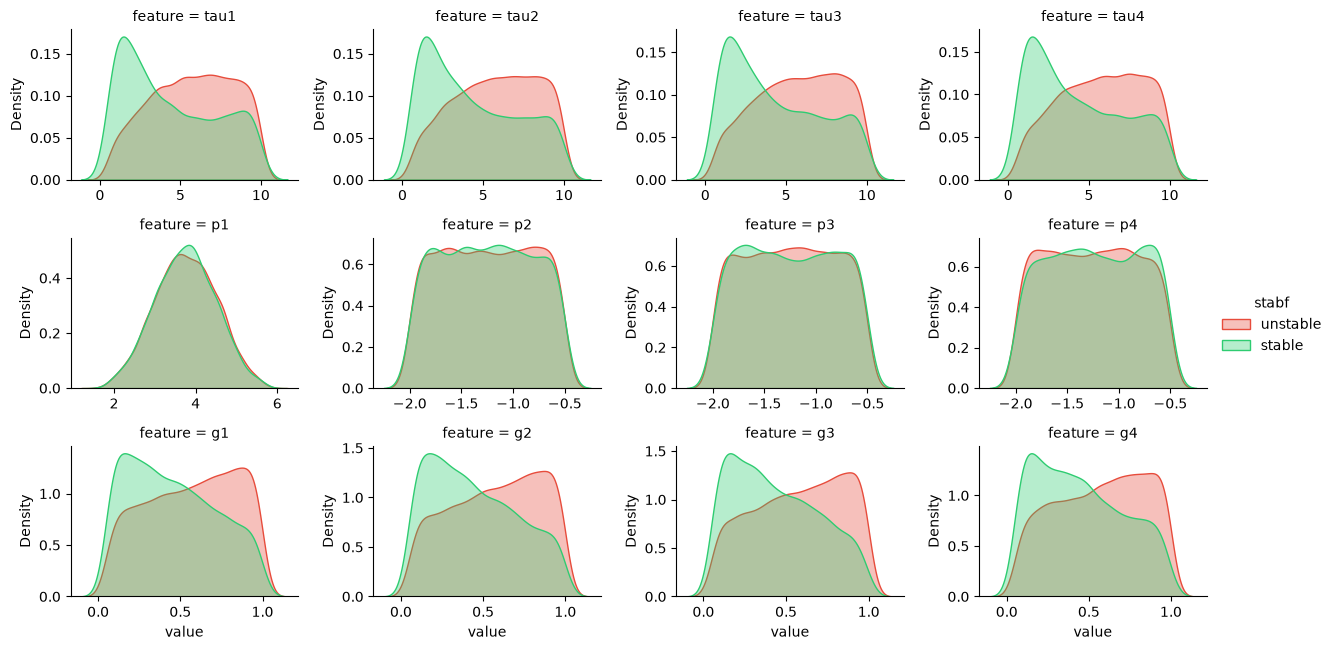

In [5]:
long_df = df.melt(id_vars="stabf", value_vars=FEATURES, var_name="feature")
g = sns.FacetGrid(long_df, col="feature", col_wrap=4, hue="stabf", sharex=False, sharey=False,
                  palette=PALETTE, height=2.2, aspect=1.4)
g.map(sns.kdeplot, "value", fill=True, alpha=0.35)
g.add_legend(title="stabf")
plt.show()

In [6]:
# Mean of each feature per class and the standardised difference between classes
summary = df.groupby("stabf")[FEATURES].mean().T
summary["diff / std"] = (summary["unstable"] - summary["stable"]) / df[FEATURES].std()
summary.round(3).sort_values("diff / std", key=abs, ascending=False)

stabf,stable,unstable,diff / std
tau2,4.353,5.759,0.512
tau4,4.378,5.744,0.498
tau3,4.385,5.741,0.494
tau1,4.395,5.735,0.489
g3,0.441,0.573,0.482
g2,0.446,0.570,0.452
g4,0.450,0.567,0.426
g1,0.453,0.566,0.411
p4,-1.237,-1.257,-0.047
p1,3.740,3.756,0.021


**Interpretation:**
- Unstable grids have, on average, **longer reaction times** (`tau`) and **higher price elasticity**
  (`g`): slow, strongly price-reactive participants make the feedback loop oscillate.
- The `p` distributions are almost identical for both classes, so power values on their own carry
  little information about stability.
- The class distributions overlap heavily for every single feature, so no single variable separates
  the classes; good performance will depend on **combinations** of features. This motivates
  comparing a linear model (Logistic Regression) with a non-linear one (Random Forest).